Correlations of enviornmental factors with solar radiation

             All_day  Daytime(6am-7pm)  Near_noon(11am-1pm)
Temperature     0.73              0.67                 0.58
Humidity       -0.23             -0.35                -0.52
Pressure        0.12              0.23                 0.27
Speed           0.07              0.11                 0.07


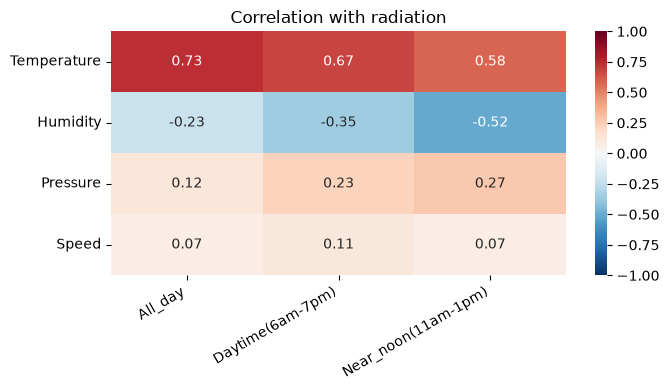

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../solar_radiation_data/SolarPrediction.csv')

time_hr=[]

for value in df['Time']:
    parts=value.split(':')
    hour=int(parts[0])
    minute=int(parts[1])
    second=int(parts[2])
    time_hr.append(hour+minute/60+second/3600)

df['Time_hr']=time_hr


env_params = ['Temperature', 'Humidity', 'Pressure','Speed']

subsets_of_day={'All_day':df , 'Daytime(6am-7pm)':df[(df['Time_hr'] >= 6) & (df['Time_hr'] <= 19)] ,
                'Near_noon(11am-1pm)':df[(df['Time_hr'] >= 11) & (df['Time_hr'] < 13)] }

corr_data={}

for name , data in subsets_of_day.items():
    corr_data[name]=data[env_params].corrwith(data['Radiation'])

corr_table=pd.DataFrame(corr_data)
print(corr_table.round(2))

#heatmap of correlation with radiation
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(corr_table, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_title('Correlation with radiation')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()

fig.savefig('../plots/correlation_with_radiation.png', dpi=150)
plt.show()